Adatszett mérete (sorok, oszlopok): (74582, 6)


,offence_date,infringement_type,offence_description,offence_location,penalty_amount,infringements
0,2023-07-01,PIN,197 (1) Stop On Path/Strip In Built-Up Area,GUNGAHLIN,132.0,1
1,2023-07-02,PIN,197 (1) Stop On Path/Strip In Built-Up Area,GRIFFITH,132.0,1
2,2023-07-02,PIN,197 (1) Stop On Path/Strip In Built-Up Area,KINGSTON,132.0,1
3,2023-07-03,PIN,197 (1) Stop On Path/Strip In Built-Up Area,BRUCE,132.0,1
4,2023-07-03,PIN,197 (1) Stop On Path/Strip In Built-Up Area,LYONS,132.0,1


1.Kérdés: Milyen alapstatisztikai mutatói vannak a kiszabott bírságoknak?

Bírságok statisztikái:
- Átlag: 702.79
- Medián: 318.00
- Szórás: 1049.03
- Minimum: 0.0
- Maximum: 37224.0


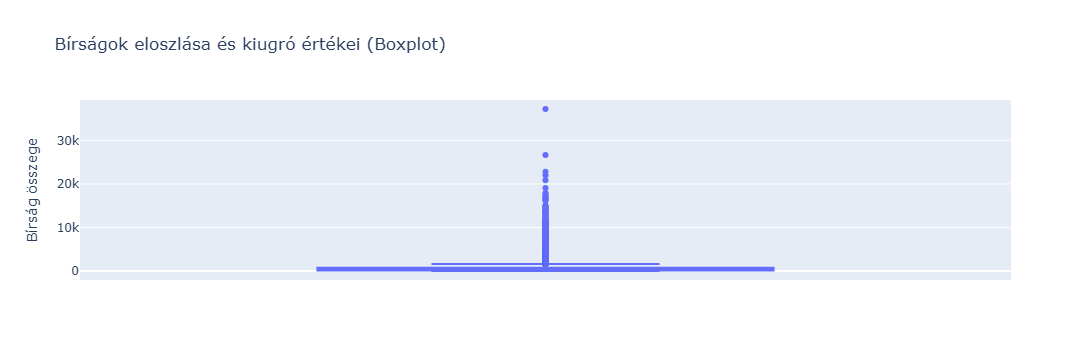

2.Kérdés: Melyik 5 helyszínen halmozódott fel a legtöbb bírság összege?
A legtöbb bírságösszeget generáló top 5 helyszín:



,offence_location,penalty_amount
25,CITY,11224184.0
109,PHILLIP,6024470.0
48,GARRAN,4431109.0
53,GREENWAY,2465222.0
55,GUNGAHLIN,2445171.0


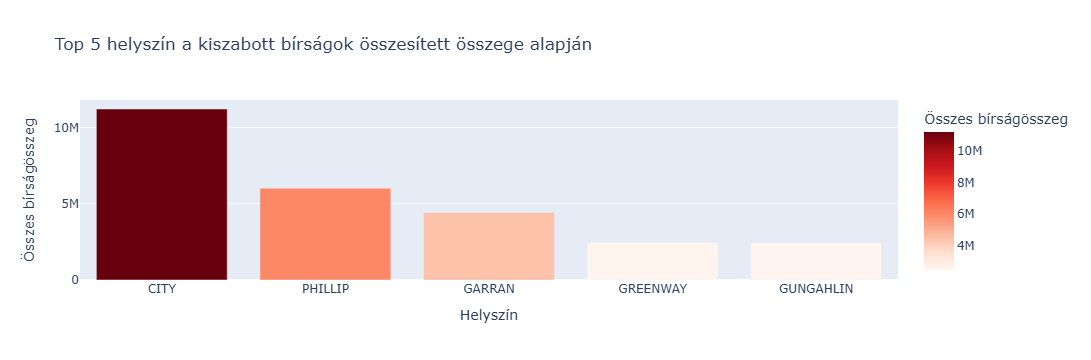

3.Kérdés: Hány olyan szabálysértés történt, ahol a bírság meghaladta az átlagos bírságösszeget, és milyen típusúak ezek?

Az átlagos bírság ($702.79) feletti esetek száma: 19516

A leggyakoribb szabálysértési típusok az átlag felettiek között:


,infringement_type,count
0,PIN,12776
1,PIN_LPR,6506
2,PIN_MAO,234


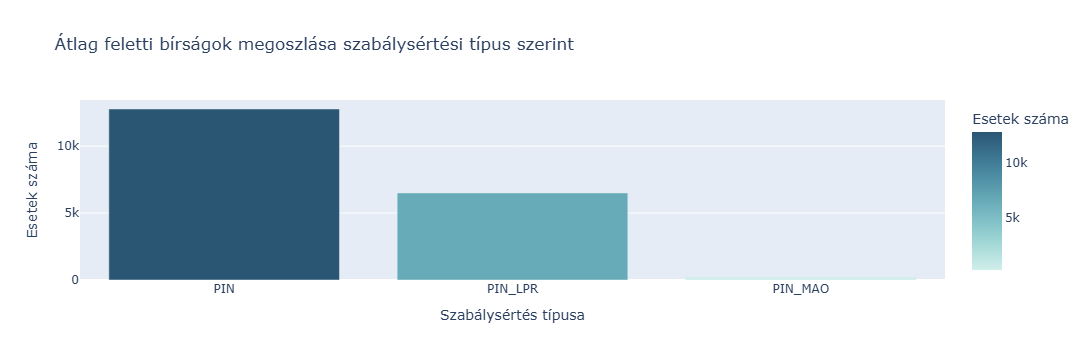

4.Kérdés: Hogyan alakult a szabálysértések száma az idő múlásával (hónapok szerint)?

Havi esetszámok (utolsó sorok):


,month,case_count
58,2026-05,1303
59,2026-06,1186
60,2026-07,1344
61,2026-08,1317
62,2026-09,1373
63,2026-10,894


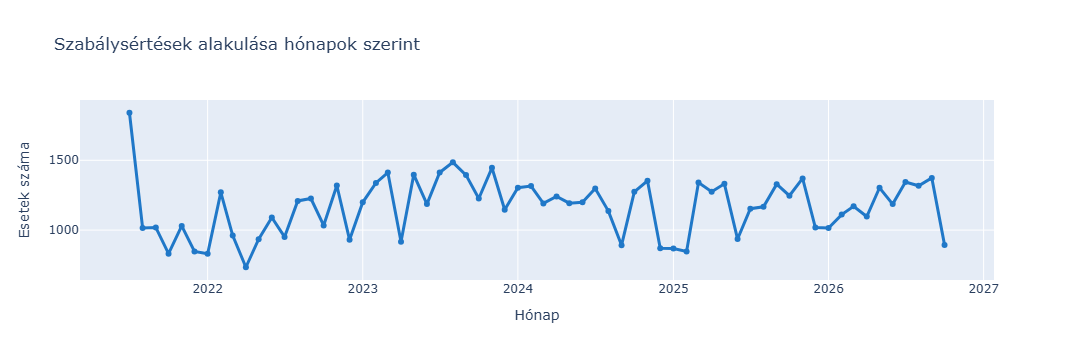

5.Kérdés: Hogyan oszlanak meg az egyes szabálysértési típusok az adatszettben?

Szabálysértési típusok darabszáma:


,infringement_type,count
0,PIN,47152
1,PIN_LPR,22949
2,PIN_MAO,4481


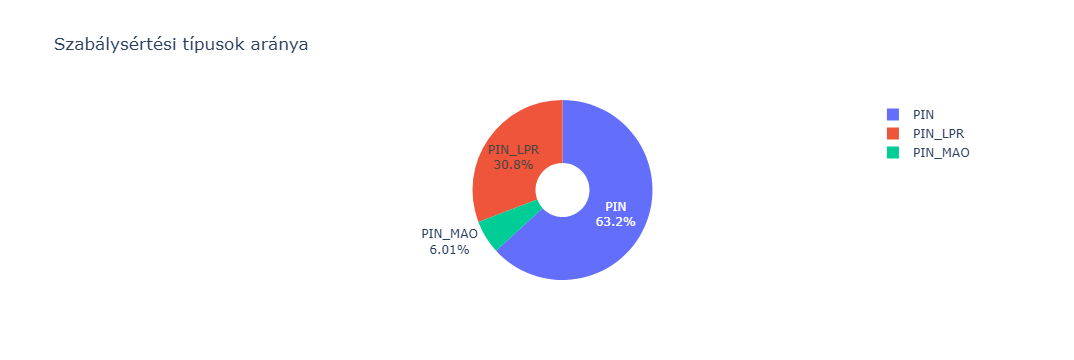

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go



adathalmaz = pd.read_csv('data.csv')

print("Adatszett mérete (sorok, oszlopok):", adathalmaz.shape)
display(adathalmaz.head())

print("1.Kérdés: Milyen alapstatisztikai mutatói vannak a kiszabott bírságoknak?")
print()
buntetesek = adathalmaz['penalty_amount'].dropna()

atlag = np.mean(buntetesek)
median = np.median(buntetesek)
szoras = np.std(buntetesek)
minimum = np.min(buntetesek)
maximum = np.max(buntetesek)

print(f"Bírságok statisztikái:")
print(f"- Átlag: {atlag:.2f}")
print(f"- Medián: {median:.2f}")
print(f"- Szórás: {szoras:.2f}")
print(f"- Minimum: {minimum}")
print(f"- Maximum: {maximum}")

fig = px.box(adathalmaz, y='penalty_amount', title='Bírságok eloszlása és kiugró értékei (Boxplot)',
             labels={'penalty_amount': 'Bírság összege'})
fig.show()




print("2.Kérdés: Melyik 5 helyszínen halmozódott fel a legtöbb bírság összege?")
top_helyszín = adathalmaz.groupby('offence_location')['penalty_amount'].sum().reset_index()
top_helyszín = top_helyszín.sort_values(by='penalty_amount', ascending=False).head(5)

print("A legtöbb bírságösszeget generáló top 5 helyszín:")
print()
display(top_helyszín)

fig = px.bar(top_helyszín, x='offence_location', y='penalty_amount', 
             title='Top 5 helyszín a kiszabott bírságok összesített összege alapján',
             labels={'offence_location': 'Helyszín', 'penalty_amount': 'Összes bírságösszeg'},
             color='penalty_amount', color_continuous_scale='Reds')
fig.show()




print("3.Kérdés: Hány olyan szabálysértés történt, ahol a bírság meghaladta az átlagos bírságösszeget, és milyen típusúak ezek?")
print()
atlagos_birsag = np.mean(adathalmaz['penalty_amount'])

atlagos_birsag_feletti = adathalmaz[adathalmaz['penalty_amount'] > atlagos_birsag]

print(f"Az átlagos bírság (${atlagos_birsag:.2f}) feletti esetek száma: {len(atlagos_birsag_feletti)}")


típusok_száma = atlagos_birsag_feletti['infringement_type'].value_counts().reset_index()
típusok_száma.columns = ['infringement_type', 'count']

print("\nA leggyakoribb szabálysértési típusok az átlag felettiek között:")
display(típusok_száma)


fig = px.bar(típusok_száma, x='infringement_type', y='count',
             title='Átlag feletti bírságok megoszlása szabálysértési típus szerint',
             labels={'infringement_type': 'Szabálysértés típusa', 'count': 'Esetek száma'},
             color='count', color_continuous_scale='Teal')
fig.show()





print("4.Kérdés: Hogyan alakult a szabálysértések száma az idő múlásával (hónapok szerint)?")
print()
adathalmaz['offence_date'] = pd.to_datetime(adathalmaz['offence_date'], errors='coerce')
adathalmaz['month'] = adathalmaz['offence_date'].dt.to_period('M').astype(str)

szamok_havonta = adathalmaz['month'].value_counts().sort_index().reset_index()
szamok_havonta.columns = ['month', 'case_count']

print("Havi esetszámok (utolsó sorok):")
display(szamok_havonta.tail(6))

fig = px.line(szamok_havonta, x='month', y='case_count', 
              markers=True,
              title='Szabálysértések alakulása hónapok szerint',
              labels={'month': 'Hónap', 'case_count': 'Esetek száma'})
fig.update_traces(line_color='rgb(32, 120, 200)', line_width=3)
fig.show()





print("5.Kérdés: Hogyan oszlanak meg az egyes szabálysértési típusok az adatszettben?")
print()
szabalysertesek = adathalmaz['infringement_type'].value_counts().reset_index()
szabalysertesek.columns = ['infringement_type', 'count']

print("Szabálysértési típusok darabszáma:")
display(szabalysertesek)


fig = px.pie(szabalysertesek, names='infringement_type', values='count',
             title='Szabálysértési típusok aránya',
             hole=0.3)
fig.update_traces(textinfo='percent+label')
fig.show()